# Is AntiFold calibrated against a measured ddG panel, and are its two scorers on one scale? The same panel with HER2 in the input

This is `03_adapt_calibration.ipynb` run again with the antigen, chain `C` of 1N8Z, in the input of
both AntiFold routes. It is a copy: only the cells listed here differ, everything else is the original, so a
number here can be set against the same number there.

| Cell | Change from 03 |
|---|---|
| parameters | `OUT_DIR` is `runs/adapt_calibration_antigen`; `NO_ANTIGEN_REFERENCE` holds 03's saved numbers |
| Part 2, helper | `run_antifold_antigen`: `antifold_score.run_antifold` plus `--antigen_chain` |
| Part 2, run | AntiFold with `--antigen_chain C`; then a control without it, and how far the flag moved the table |
| Part 3, scoring | `antifold_seq` with chains B, A and C in the input and only B and A scored; a control without C |
| Part 6 (new) | antigen against no antigen on the same variants |
| text | the lines that said "no antigen" |

Neither `antifold_score` nor `design_pipeline` is edited. Neither takes an antigen chain today, so the helpers in
Parts 2 and 3 are copies of their code with one more argument. Moving them into those modules is a separate change.

Twenty-two Fab variants of trastuzumab with SPR-derived ddG and a standard
deviation on each (ADAPT, Vivcharuk et al. 2017; the `adapt_fab_ddg` block of
`data/benchmarks/trastuzumab_mutation_evidence.csv`). Eleven singles, seven
doubles, four triples, all at four sites in CDR-H1, CDR-H3, CDR-L1 and CDR-L2.
Small, but measured on one instrument against one batch-matched parent, which
is what makes the combinations usable: a double's ddG and its singles' ddGs are
on the same scale, so the departure from additivity is a number and not an
artifact of pooling studies.

Three questions, in order, and the third is the one that changes the pipeline:

1. **Does `antifold`'s matrix lookup rank the singles?** Spearman against ddG,
   and in particular whether the two known losses - `L:S50F` and `L:S50W`, the
   only two variants in the panel that bind *worse* - come out at the bottom.
2. **Does `antifold_seq` rank the combinations?** The same question where the
   matrix lookup has no answer at all.
3. **Are the two on one scale?** `score_antifold` and `score_antifold_seq` are
   separate columns in a scored table, and a shortlist has to be cut on
   something. If the additive sum of a combination's singles' matrix scores is
   a linear function of its `antifold_seq` score with slope near 1, the two
   columns can be read as one ranking. If it is not, they cannot, and the
   pipeline has to keep them apart - which is what `matrices.score_candidates`
   already does by refusing to sum singles.

| Part | What it does | Reads | Writes |
|---|---|---|---|
| 1 | Load the block, group rows into variants, **check the numbering against 1N8Z** | the benchmark, the PDB | a variant table |
| 2 | AntiFold once with chain C in context, parsed to `LogProbMatrix`; the 11 singles scored off it; a no-antigen control | the PDB | `OUT_DIR/antifold`, `OUT_DIR/antifold_noantigen` |
| 3 | The 7 doubles and 4 triples (and the singles) scored with `antifold_seq`, chain C in context; a no-antigen control | the panel | `OUT_DIR/scores_antigen`, `OUT_DIR/scores_noantigen` |
| 4 | Additive matrix prediction vs `antifold_seq`: one scale, or two? | Parts 2 and 3 | nothing |
| 5 | The measured epistasis in this panel as the yardstick for Part 4 | the benchmark | nothing |
| 6 | Antigen against no antigen, same variants | Parts 2 and 3, 03's saved numbers | nothing |

**Part 1 is a gate.** The benchmark numbers its variants in 1N8Z's own PDB
numbering and names the chains `H` and `L`; this file labels them `B` and `A`.
A chain map that is right for three sites and wrong for the fourth produces a
full set of plausible scores for the wrong residues, and nothing downstream can
tell. So every variant's wild-type residue is checked against the structure
before a model is loaded, twice - once here and once by
`enumerate_variants(only=...)`, which raises on a wt that disagrees - and the
rest of the notebook refuses to run if either check fails.

Run it on the GPU box, in the environment that holds this package (Env A);
AntiFold itself is reached by path (Env B) and is run with the GPUs hidden,
because AntiFold 0.4.0 moves a batch to a visible device inside a forked
data-loader worker even when asked for the CPU. One structure is seconds, and
22 `antifold_seq` passes are under a minute.

In [1]:
# --- parameters -------------------------------------------------------------

# The local 1N8Z. None searches the places a copy usually lands (printed below
# if the search fails). Nothing here downloads: a structure that arrived by
# another route is a different structure, and every position in this notebook
# is an index into this one file.
PDB_PATH = None

# The benchmark. `adapt_fab_ddg` is not a column in the file - it is the block
# this notebook reads, and these conditions are its definition: the ADAPT 2017
# study, the Fab format, and a reported ddG. On the file as of 2026-10-31 they
# select 22 rows, and no other row in the file carries a ddG at all.
BENCHMARK_PATH = None
BLOCK_NAME = "adapt_fab_ddg"
BLOCK_STUDY = "adapt2017"
BLOCK_FORMAT = "Fab"
EXPECTED_VARIANTS = 22
EXPECTED_SIZES = {1: 11, 2: 7, 3: 4}      # singles, doubles, triples

# 1N8Z is the trastuzumab Fab bound to HER2 (chain C; its length is printed in Part 1). The heavy chain is 'B',
# not 'H', and the benchmark writes its variants as H: and L:, so the two
# namings have to be mapped. Both halves are asserted against the file in Part 1.
HEAVY_CHAIN = "B"
LIGHT_CHAIN = "A"
ANTIGEN_CHAIN = "C"
CHAIN_MAP = {"H": HEAVY_CHAIN, "L": LIGHT_CHAIN}

# The two losses in the panel. Named here, as a parameter, so Part 2's check on
# them is a stated prediction and not a sentence written after the fact.
EXPECTED_WORST = ("L:S50F", "L:S50W")

# Env B. ANTIFOLD_PYTHON is the interpreter that can `import antifold` (0.4.0
# or later, for score_sequence_in_complex); ANTIFOLD_SRC is AntiFold's source
# folder, the one that holds antifold/main.py and models/model.pt.
ANTIFOLD_PYTHON = None     # None -> $DESIGN_PIPELINE_ANTIFOLD, then "python"
ANTIFOLD_SRC = None        # None -> $ANTIFOLD_SRC
ANTIFOLD_WEIGHTS = None    # None -> <ANTIFOLD_SRC>/models/model.pt if it exists

OUT_DIR = "runs/adapt_calibration_antigen"

# Part 4's criterion, written down before the number is seen. A slope outside
# this band means the two columns do not share a scale, whatever their
# correlation; LINEARITY_GAIN is how much R^2 a quadratic term may buy before
# "linear" stops being a fair description.
SLOPE_NEAR_ONE = (0.8, 1.25)
LINEARITY_GAIN = 0.02

# Part 5's yardstick as it was handed to this notebook, in kcal/mol. Recomputed
# from the file in Part 5; a disagreement means the file has changed under the
# number and the comparison is void.
REPORTED_EPISTASIS = {"mean": 0.057, "sd": 0.186, "max": 0.37,
                      "median_measurement_sd": 0.165}
TOLERANCE = 0.01

# What 03_adapt_calibration.ipynb printed without the antigen (commit e14d035, run on the GPU node on
# 2026-10-31, read off its saved outputs). Part 6 prints this run next to it, and a live control is run as well.
NO_ANTIGEN_REFERENCE = {
    "singles_rho": +0.291,    # matrix lookup on the 11 singles, Spearman against -ddG
    "combos_rho": -0.655,     # antifold_seq on the 11 combinations
    "all22_rho": -0.667,      # antifold_seq on all 22, one ranking
    "worst_two_at_bottom": False,
    "one_scale": False,
}
REFERENCE_TOLERANCE = 0.01    # how closely the live control must reproduce the saved numbers


In [2]:
import csv
import os
import re
import subprocess
import sys
import types
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

# Run from the repo root whatever the working directory, so the relative paths
# below mean one thing and `antifold_score` is importable.
root = Path.cwd().resolve()
while not (root / "pyproject.toml").is_file() and root != root.parent:
    root = root.parent
if not (root / "pyproject.toml").is_file():
    raise RuntimeError(f"no repo root above {Path.cwd()}: pyproject.toml not found")
os.chdir(root)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from antifold_score import run_antifold
from design_pipeline import _diagnostics, metrics, numbering, structures
from design_pipeline.api import score_variants
from design_pipeline.matrices import IndexMismatchError, from_position_mapping
from design_pipeline.structures import AMINO_ACIDS, Complex
from design_pipeline.variants import enumerate_variants, make_id

PDB_CANDIDATES = (
    Path("data/structures/1N8Z.pdb"),
    Path("data/1N8Z.pdb"),
    Path.home() / ".cache" / "design_pipeline" / "pdb" / "1n8z.pdb",
)
BENCHMARK_CANDIDATES = (
    Path("data/benchmarks/trastuzumab_mutation_evidence.csv"),
    Path("trastuzumab_mutation_evidence.csv"),
    Path("data/trastuzumab_mutation_evidence.csv"),
)


def resolve(override, candidates, what):
    if override is not None:
        path = Path(override).expanduser()
        if not path.is_file():
            raise FileNotFoundError(f"{what} does not exist: {path}")
        return path
    for candidate in candidates:
        if candidate.is_file():
            return candidate
    looked = "\n".join(f"  {c}" for c in candidates)
    raise FileNotFoundError(
        f"no {what} found. Looked in:\n{looked}\nSet the parameter above."
    )


pdb = resolve(PDB_PATH, PDB_CANDIDATES, "local 1N8Z")
benchmark = resolve(BENCHMARK_PATH, BENCHMARK_CANDIDATES, "benchmark csv")
out_dir = Path(OUT_DIR)
antifold_python = ANTIFOLD_PYTHON or os.environ.get("DESIGN_PIPELINE_ANTIFOLD") or "python"
antifold_src = ANTIFOLD_SRC or os.environ.get("ANTIFOLD_SRC")

print(f"repo root:       {root}")
print(f"structure:       {pdb}  ({pdb.stat().st_size:,} bytes)")
print(f"benchmark:       {benchmark}  ({benchmark.stat().st_size:,} bytes)")
print(f"out_dir:         {out_dir.resolve()}")
print(f"this python:     {sys.executable}")
print(f"antifold python: {antifold_python}")
print(f"antifold src:    {antifold_src or 'NOT SET (Parts 2-5 will stop)'}")
print(f"antigen chain:    {ANTIGEN_CHAIN} (in the model's input)")
print(f"anarci:          {'available' if numbering.available() else 'not installed (imgt column stays empty)'}")

repo root:       /scratch/foertsch/protecher_pr14_adapt/tree
structure:       data/structures/1N8Z.pdb  (703,809 bytes)
benchmark:       trastuzumab_mutation_evidence.csv  (1,507,641 bytes)
out_dir:         /scratch/foertsch/protecher_pr14_adapt/tree/runs/adapt_calibration_antigen
this python:     /scratch/foertsch/protecher/.venv/bin/python
antifold python: /scratch/foertsch/protecher_tools/antifold/venv/bin/python
antifold src:    /scratch/foertsch/protecher_tools/antifold/src
antigen chain:    C (in the model's input)
anarci:          not installed (imgt column stays empty)


## Part 1 - the panel, and the numbering

Three steps. Select the block; group its rows back into variants, because the
file is one row per measurement and a variant can own several; then check every
variant against the structure.

The grouping matters for honesty about *n*. The 22 ddG values are 22 rows, one
per variant, but the block holds 50: the same four triples also carry an
absolute KD, an on-rate and an off-rate, two more triples appear with nothing
but a purification note, and one site appears only as a structural rejection.
Collapsing the block by variant rather than counting rows is what keeps 22 from
quietly becoming 50.

The numbering check is the gate. The benchmark states its own numbering as
"1N8Z PDB numbering" and names the chains `H` and `L`; this file labels them
`B` and `A` and, for those two chains only, labels residues 1..n contiguously -
so the file's own labels and this package's 1-based `position` coincide *in this
file*, which is measured below rather than assumed. The check that actually
protects the rest of the notebook is simpler than any of that: the residue the
benchmark says is wild type has to be the residue 1N8Z has at that chain and
position. Four distinct sites, 22 variants, every one checked.

In [3]:
raw = pd.read_csv(benchmark)
needed = [
    "study", "format", "variant", "metric", "value", "units",
    "ddg_reported_kcal_mol", "ddg_sd_kcal_mol", "numbering_source",
    "affinity_improvement_reported", "evidence_id", "assay",
]
absent = [c for c in needed if c not in raw.columns]
if absent:
    raise ValueError(f"{benchmark} is missing columns this notebook reads: {absent}")

# The block, and the definition of it printed rather than implied.
in_block = (raw["study"] == BLOCK_STUDY) & (raw["format"] == BLOCK_FORMAT)
block = raw[in_block]
has_ddg = block["ddg_reported_kcal_mol"].notna()
ddg_rows = block[has_ddg]
elsewhere = int((raw["ddg_reported_kcal_mol"].notna() & ~in_block).sum())

print(f"block {BLOCK_NAME!r} = study {BLOCK_STUDY!r} and format {BLOCK_FORMAT!r} and a reported ddG")
print(f"  {len(raw):,} rows in the file")
print(f"  {len(block)} rows in the block ({block['variant'].nunique()} distinct variants)")
print(f"  {len(ddg_rows)} of them carry a ddG")
print(f"  {elsewhere} rows elsewhere in the file carry a ddG, so this block is the whole ddG panel")
print()
print("what the rest of the block holds, by metric:")
for metric_name, count in block.loc[~has_ddg, "metric"].value_counts().items():
    print(f"  {metric_name:<26}{count:>4}")
print()
print(f"numbering the block declares: {sorted(set(ddg_rows['numbering_source']))}")
print(f"assay: {sorted(set(ddg_rows['assay']))}")

block 'adapt_fab_ddg' = study 'adapt2017' and format 'Fab' and a reported ddG
  929 rows in the file
  50 rows in the block (26 distinct variants)
  22 of them carry a ddG
  0 rows elsewhere in the file carry a ddG, so this block is the whole ddG panel

what the rest of the block holds, by metric:
  apparent_KD                 10
  KD                           5
  kon                          5
  koff                         5
  purification_quality         2
  structural triage            1

numbering the block declares: ['1N8Z PDB numbering']
assay: ['SPR; batch-matched parent normalization']


In [4]:
# One row per variant, and the variant string turned into mutations this
# package can index with. Two namings travel together from here on: `label` is
# the benchmark's (H:/L:, its own numbering) and `variant_id` is this package's,
# over the chains 1N8Z actually has.
TOKEN = re.compile(r"^(?P<chain>[A-Za-z0-9]+):(?P<wt>[A-Z])(?P<position>\d+)(?P<mut>[A-Z])$")


def parse_benchmark_variant(text):
    '''[(chain, position, wt, mut)] as the benchmark writes it.'''
    mutations = []
    for token in str(text).split(";"):
        match = TOKEN.match(token.strip())
        if match is None:
            raise ValueError(f"{text!r}: {token.strip()!r} is not a substitution like H:D31R")
        mutations.append((match["chain"], int(match["position"]), match["wt"], match["mut"]))
    if not mutations:
        raise ValueError(f"{text!r} names no substitution")
    return mutations


def remap(mutations):
    '''The same mutations over 1N8Z's chain ids. An unmapped chain is an error.'''
    out = []
    for chain, position, wt, mut in mutations:
        if chain not in CHAIN_MAP:
            raise KeyError(f"chain {chain!r} is not in CHAIN_MAP {CHAIN_MAP}")
        out.append((CHAIN_MAP[chain], position, wt, mut))
    return out


def label_of(mutations):
    return "+".join(f"{c}:{w}{p}{m}" for c, p, w, m in sorted(mutations))


records = []
for row in ddg_rows.itertuples():
    benchmark_mutations = parse_benchmark_variant(row.variant)
    structure_mutations = remap(benchmark_mutations)
    records.append({
        "evidence_id": row.evidence_id,
        "label": label_of(benchmark_mutations),
        "variant_id": make_id(structure_mutations),
        "n_mut": len(structure_mutations),
        "ddg": float(row.ddg_reported_kcal_mol),
        "ddg_sd": float(row.ddg_sd_kcal_mol),
        "fold": float(row.affinity_improvement_reported),
        "mutations": tuple(sorted(structure_mutations)),
    })

panel = pd.DataFrame(records).sort_values(["n_mut", "ddg"]).reset_index(drop=True)

duplicated = panel["variant_id"].duplicated(keep=False)
if duplicated.any():
    raise ValueError(
        "a variant has more than one ddG row, so grouping by variant would have to "
        f"average measurements:\n{panel[duplicated]}"
    )
if len(panel) != EXPECTED_VARIANTS:
    raise ValueError(f"expected {EXPECTED_VARIANTS} variants in the block, grouped {len(panel)}")
sizes = panel["n_mut"].value_counts().to_dict()
if sizes != EXPECTED_SIZES:
    raise ValueError(f"expected {EXPECTED_SIZES} by mutation count, got {sizes}")

print(f"{'evidence':<10}{'benchmark label':<30}{'1N8Z id':<30}{'n':>2}{'ddG':>8}{'SD':>7}{'fold':>8}")
print("-" * 95)
for row in panel.itertuples():
    print(f"{row.evidence_id:<10}{row.label:<30}{row.variant_id:<30}{row.n_mut:>2}"
          f"{row.ddg:>8.2f}{row.ddg_sd:>7.2f}{row.fold:>8.1f}")
print("-" * 95)
print(f"{len(panel)} variants: "
      + ", ".join(f"{n} with {k} mutation(s)" for k, n in sorted(sizes.items())))
print(f"ddG spans {panel['ddg'].min():+.2f} to {panel['ddg'].max():+.2f} kcal/mol "
      f"(lower is tighter binding); measurement SD {panel['ddg_sd'].min():.2f} to "
      f"{panel['ddg_sd'].max():.2f}, median {panel['ddg_sd'].median():.3f}")
print()
print(f"the {int((panel['ddg'] > 0).sum())} variants that bind worse than the parent: "
      + ", ".join(panel.loc[panel['ddg'] > 0, 'label']))

evidence  benchmark label               1N8Z id                        n     ddG     SD    fold
-----------------------------------------------------------------------------------------------
TZM-056   H:D102F                       B:D102F                        1   -0.87   0.18     4.2
TZM-054   H:D31K                        B:D31K                         1   -0.70   0.25     3.2
TZM-058   H:D102H                       B:D102H                        1   -0.69   0.17     3.3
TZM-053   H:D31R                        B:D31R                         1   -0.59   0.18     2.8
TZM-060   L:D28K                        A:D28K                         1   -0.52   0.02     2.4
TZM-059   H:D102M                       B:D102M                        1   -0.47   0.11     2.2
TZM-057   H:D102K                       B:D102K                        1   -0.38   0.07     1.9
TZM-061   L:D28R                        A:D28R                         1   -0.31   0.16     1.7
TZM-055   H:D31M                        

In [5]:
# The block's other rows, grouped onto the same variants: the absolute KD panel
# the four triples also carry. Not used in any correlation below - it is here
# because "22 variants" and "50 rows" have to be reconcilable on screen.
context = block.loc[~has_ddg, ["variant", "metric", "value", "units"]]
if len(context):
    wide = context.pivot_table(index="variant", columns="metric", values="value", aggfunc="first")
    print("the same variants' direct measurements (no ddG attached):")
    print(wide.to_string(float_format=lambda v: f"{v:g}"))
    in_panel = set(panel["label"])
    seen = {v: (v if v == "WT" else label_of(parse_benchmark_variant(v))) for v in wide.index}
    print()
    print(f"of those, also in the ddG panel: {sorted(l for l in seen.values() if l in in_panel)}")
    print(f"not in it: {sorted(l for l in seen.values() if l not in in_panel)}")
    print("The two 'heterogeneous' triples and the rejected L:S50Y are in the block but")
    print("carry no ddG, which is why the panel is 22 and not 25.")

the same variants' direct measurements (no ddG attached):
metric                   KD apparent_KD     koff        kon purification_quality           structural triage
variant                                                                                                     
H:D102F;H:D31K;L:D28K   1.9         4.5  1.1e-05  6100000.0                  NaN                         NaN
H:D102F;H:D31K;L:D28R   2.5         5.4  1.7e-05  6800000.0                  NaN                         NaN
H:D102F;H:D31M;L:D28K   2.9         4.6  1.4e-05  5100000.0                  NaN                         NaN
H:D102F;H:D31M;L:D28R   4.0         5.2  1.9e-05  5000000.0                  NaN                         NaN
H:D102F;H:D31R;L:D28K   NaN         NaN      NaN        NaN        heterogeneous                         NaN
H:D102F;H:D31R;L:D28R   NaN         NaN      NaN        NaN        heterogeneous                         NaN
L:S50Y                  NaN         NaN      NaN        NaN           

In [6]:
# --- the numbering check. Nothing below this cell runs if it fails. ----------
chains = structures.chain_ids(pdb)
roles = {"heavy": HEAVY_CHAIN, "light": LIGHT_CHAIN, "antigen": ANTIGEN_CHAIN}
unknown = {role: chain for role, chain in roles.items() if chain not in chains}
if unknown:
    raise KeyError(
        f"chains named in the parameters that {pdb} does not have: {unknown}. Present: {chains}"
    )

sequences = {chain: structures.chain_sequence(pdb, chain) for chain in chains}
residue_ids = {chain: structures.chain_residue_ids(pdb, chain) for chain in chains}

print(f"{'chain':<7}{'role':<9}{'len':>5}{'first':>8}{'last':>8}{'labels are 1..n':>18}")
print("-" * 56)
coincide = {}
for chain in chains:
    labels = residue_ids[chain]
    numeric = all(label.isdigit() for label in labels)
    contiguous = numeric and [int(label) for label in labels] == list(range(1, len(labels) + 1))
    coincide[chain] = contiguous
    role = {v: k for k, v in roles.items()}.get(chain, "-")
    print(f"{chain:<7}{role:<9}{len(sequences[chain]):>5}{labels[0]:>8}{labels[-1]:>8}"
          f"{('yes' if contiguous else 'NO'):>18}")
print()
print("The block declares '1N8Z PDB numbering'. For chains "
      f"{HEAVY_CHAIN} and {LIGHT_CHAIN} the file's own labels run 1..n contiguously "
      f"({coincide[HEAVY_CHAIN] and coincide[LIGHT_CHAIN]}), so the file's")
print("numbering and this package's 1-based `position` coincide here. That is a")
print("property of this file, not of PDB numbering, and it is why the check below is")
print("on residue identity rather than on the numbering scheme.")

chain  role       len   first    last   labels are 1..n
--------------------------------------------------------
A      light      214       1     214               yes
B      heavy      220       1     220               yes
C      antigen    581       1     607                NO

The block declares '1N8Z PDB numbering'. For chains B and A the file's own labels run 1..n contiguously (True), so the file's
numbering and this package's 1-based `position` coincide here. That is a
property of this file, not of PDB numbering, and it is why the check below is
on residue identity rather than on the numbering scheme.


In [7]:
# Every site the panel touches, against the structure. One row per distinct
# (chain, position), with the variants that use it, so a mismatch names what it
# would have broken.
sites = {}
for row in panel.itertuples():
    for chain, position, wt, mut in row.mutations:
        sites.setdefault((chain, position, wt), []).append(row.label)

print(f"{'site (1N8Z)':<14}{'benchmark says wt':>19}{'1N8Z has':>10}{'pdb label':>11}"
      f"{'variants':>10}  verdict")
print("-" * 79)
mismatches = []
for (chain, position, wt), used_by in sorted(sites.items()):
    sequence = sequences[chain]
    inside = 0 < position <= len(sequence)
    here = sequence[position - 1] if inside else "-"
    label = residue_ids[chain][position - 1] if inside else "-"
    ok = inside and here == wt
    if not ok:
        mismatches.append((chain, position, wt, here))
    print(f"{f'{chain}:{position}':<14}{wt:>19}{here:>10}{label:>11}{len(used_by):>10}  "
          f"{'ok' if ok else 'MISMATCH'}")

if mismatches:
    raise AssertionError(
        "the numbering does not line up with the structure: "
        + "; ".join(f"{c}:{p} benchmark says {w}, 1N8Z has {h}" for c, p, w, h in mismatches)
        + ". Every score below would be a real number for the wrong residue. Check "
        "CHAIN_MAP and the block's numbering_source before going on."
    )

# The second, independent check: enumerate_variants(only=...) re-parses every id
# and calls _check_wt against the structure itself. It is also the variant table
# Part 3 scores, so the gate and the artifact are one step.
complex_ = Complex(paths=(pdb,), output_dir=out_dir, config={"source": str(pdb)})
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)   # anarci absent: imgt stays empty
    variants = enumerate_variants(
        complex_, chain=HEAVY_CHAIN, output_dir=out_dir / "variants",
        only=list(panel["variant_id"]),
    )

NUMBERING_OK = True
print()
print(f"NUMBERING CHECK PASSED: {len(sites)} distinct sites, {len(panel)} variants, "
      f"{variants.rows} mutation rows, {variants.candidates} candidates.")
print(f"variant table: {variants.path}")

site (1N8Z)     benchmark says wt  1N8Z has  pdb label  variants  verdict
-------------------------------------------------------------------------------
A:28                            D         D         28         6  ok
A:50                            S         S         50         2  ok
B:31                            D         D         31        14  ok
B:102                           D         D        102        15  ok

NUMBERING CHECK PASSED: 4 distinct sites, 22 variants, 37 mutation rows, 22 candidates.
variant table: runs/adapt_calibration_antigen/variants/requested.parquet


## Part 2 - the singles, off the matrix

One forward pass over the backbone, read as a `LogProbMatrix` per chain, and
`score = M[position, mut] - M[position, wt]` per single. That subtraction is the
whole of the `antifold` scorer, and the reason it lives in a module of this
package rather than in each adapter is that a row off by one still yields a real
log-odds - for the wrong residue.

Two things about this run are deliberate and both cost something:

* **Antigen in context.** The AntiFold command gets `--antigen_chain C`, which
  puts chain C's backbone in the model's input (AntiFold's own antibody-antigen
  mode). The table still has its rows for B and A, which is what this Part
  reads; the cell below prints which chains it holds. `antifold_seq` gets chains
  B, A and C when its coordinates are loaded and scores only B and A, so the
  antigen is context and its sequence is never scored. Both scorers see HER2, so
  Parts 2 and 3 are still comparable, which Part 4 needs. A control without the
  antigen runs in the same notebook and shows how far the flag moved the numbers;
  if it moved nothing, every result below is 03's again.
* **CPU.** `run_antifold` hides the GPUs, because AntiFold 0.4.0 moves a batch
  to a visible device inside a forked data-loader worker even with
  `--device cpu`. One structure is seconds.

The parser detects its columns rather than assuming them, and prints what it
found. No fixture of AntiFold's real output exists in this repo yet
(`notebooks/02_antifold_capture.ipynb` Part 5 is still open), so a parser here
that silently assumed a name would be the exact mistake that notebook is
arranged to prevent. If the detection fails it raises with the column list in
the message.

In [8]:
# Two helpers, local to this notebook. `antifold_score.run_antifold` and
# `design_pipeline/adapters/_antifold_seq.py` take no antigen chain, so these are copies
# of their code with one more argument. Neither module is edited here.

def run_antifold_antigen(pdb, heavy, light, antigen, out_dir, src, executable=None):
    """`antifold_score.run_antifold` plus `--antigen_chain` (None leaves it out). Returns the table.

    Started from AntiFold's source folder, with CUDA hidden, as `run_antifold` does. With an
    antigen AntiFold switches to its custom chain mode and names the table after the chains it
    was given, so the table is found by pattern: `<pdb>_<heavy><light>*.csv`, exactly one.
    """
    out_dir = Path(out_dir).resolve()
    command = [
        executable or sys.executable, "antifold/main.py", "--pdb_file", str(Path(pdb).resolve()),
        "--heavy_chain", heavy, "--light_chain", light,
        *(["--antigen_chain", antigen] if antigen else []),
        "--out_dir", str(out_dir), "--device", "cpu",
    ]
    done = subprocess.run(command, cwd=src, env={**os.environ, "CUDA_VISIBLE_DEVICES": ""},
                          capture_output=True, text=True)
    tables = sorted(out_dir.glob(f"{Path(pdb).stem}_{heavy}{light}*.csv"))
    if done.returncode != 0 or len(tables) != 1:
        raise RuntimeError(
            f"AntiFold failed or left an unexpected set of tables (exit {done.returncode}; tables: "
            f"{[t.name for t in tables]}). Last output:\n" + "\n".join((done.stdout + done.stderr).splitlines()[-12:])
        )
    return tables[0]


# `antifold_seq` with the antigen as context. It loads the adapter's own ComplexScorer by path
# (that file imports only the standard library and AntiFold), gives it chains heavy, light and
# antigen, and then keeps only heavy and light in `sequences`, so the antigen's backbone is in
# every forward pass and its sequence is never scored. Without --antigen this is the adapter's
# own run, which is what the control uses. Written to disk and run by AntiFold's interpreter.
ANTIFOLD_SEQ_ANTIGEN_SCRIPT = '''
import argparse
import importlib.util
import os
import sys
from pathlib import Path

parser = argparse.ArgumentParser()
parser.add_argument("--adapter", type=Path, required=True)
parser.add_argument("--pdb", type=Path, required=True)
parser.add_argument("--out_dir", type=Path, required=True)
parser.add_argument("--mutations_csv", type=Path, required=True)
parser.add_argument("--heavy", required=True)
parser.add_argument("--light", required=True)
parser.add_argument("--antigen")
parser.add_argument("--weights", type=Path)
args = parser.parse_args()

os.environ["CUDA_VISIBLE_DEVICES"] = ""
spec = importlib.util.spec_from_file_location("_antifold_seq", args.adapter)
seq = importlib.util.module_from_spec(spec)
sys.modules["_antifold_seq"] = seq
spec.loader.exec_module(seq)

candidates = seq.read_candidates(args.mutations_csv)
chains = [args.heavy, args.light] + ([args.antigen] if args.antigen else [])
scorer = seq.ComplexScorer(args.pdb, chains, device="cpu", weights=args.weights)
scored_chains = (args.heavy, args.light)
scorer.sequences = {c: s for c, s in scorer.sequences.items() if c in scored_chains}
missing = [c for c in scored_chains if c not in scorer.sequences]
if missing:
    sys.exit(f"chains {missing} are not in the structure")
rows = seq.score_with_complex(scorer, candidates)
args.out_dir.mkdir(parents=True, exist_ok=True)
path = seq.write_scores(args.out_dir / "antifold_seq.csv", rows)
print(f"chains in the input: {chains}; scored: {list(scorer.sequences)}")
print(f"{sum(r[1] is not None for r in rows)} of {len(rows)} candidates scored -> {path}")
'''


In [9]:
if not NUMBERING_OK:
    raise RuntimeError("Part 1 did not pass")
if not antifold_src:
    raise RuntimeError(
        "ANTIFOLD_SRC is not set: the matrix route needs AntiFold's source folder "
        "(the one holding antifold/main.py and models/model.pt). Set the parameter "
        "ANTIFOLD_SRC or the environment variable, and rerun from here."
    )

print(f"AntiFold {antifold_python!r} on {pdb.name}, chains heavy={HEAVY_CHAIN} "
      f"light={LIGHT_CHAIN} antigen={ANTIGEN_CHAIN}, from {antifold_src}")
table_path = run_antifold_antigen(
    pdb, HEAVY_CHAIN, LIGHT_CHAIN, ANTIGEN_CHAIN, out_dir / "antifold", Path(antifold_src),
    executable=antifold_python,
)
print(f"\ntable: {table_path}  ({table_path.stat().st_size:,} bytes)")

raw_table = pd.read_csv(table_path)
print(f"shape: {raw_table.shape[0]} rows x {raw_table.shape[1]} columns")
print(f"columns: {list(raw_table.columns)}")
print()
print(raw_table.head(4).to_string())

AntiFold '/scratch/foertsch/protecher_tools/antifold/venv/bin/python' on 1N8Z.pdb, chains heavy=B light=A antigen=C, from /scratch/foertsch/protecher_tools/antifold/src



table: /scratch/foertsch/protecher_pr14_adapt/tree/runs/adapt_calibration_antigen/antifold/1N8Z_BAC.csv  (187,995 bytes)
shape: 1015 rows x 27 columns
columns: ['pdb_posins', 'pdb_chain', 'pdb_res', 'top_res', 'pdb_pos', 'perplexity', 'assumed_region', 'A', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'P', 'Q', 'R', 'S', 'T', 'V', 'W', 'Y']

   pdb_posins pdb_chain pdb_res top_res  pdb_pos  perplexity assumed_region        A        C        D        E        F        G        H        I        K       L       M        N        P        Q        R        S        T        V        W        Y
0           1         B       E       M        1      1.4065           FWH1  -5.4608  -7.5297  -5.9835  -5.9073  -7.0817  -4.6097  -6.7700  -6.4426  -6.2203 -6.1452 -0.0532  -6.3563  -5.4310  -6.2249  -6.0951  -5.0834  -5.8638  -5.5188  -8.2552  -7.6873
1           2         B       V       V        2      1.0573           FWH1  -9.0209 -11.6773 -12.1557  -8.6077 -11.6771 -10.8078 -12.599

In [10]:
# Control: the same call without the antigen, into its own folder, and the largest change in any
# log probability on the antibody chains. If the flag did nothing the change is 0 and every number
# below would be 03's again; the cell says so rather than carrying on silently.
control_path = run_antifold_antigen(
    pdb, HEAVY_CHAIN, LIGHT_CHAIN, None, out_dir / "antifold_noantigen", Path(antifold_src),
    executable=antifold_python,
)
control_table = pd.read_csv(control_path)
residue_columns_here = [a for a in AMINO_ACIDS if a in raw_table.columns and a in control_table.columns]
print(f"control table: {control_path.name}, {control_table.shape[0]} rows; "
      f"amino-acid columns compared: {len(residue_columns_here)}")
print(f"rows per chain, with antigen: {raw_table['pdb_chain'].astype(str).value_counts().to_dict()}")
print(f"rows per chain, without:      {control_table['pdb_chain'].astype(str).value_counts().to_dict()}")
print()
print(f"{'chain':<7}{'rows':>6}{'max |dlogP|':>14}{'mean |dlogP|':>14}{'top residue changed':>22}")
print("-" * 63)
effect = {}
for chain in (HEAVY_CHAIN, LIGHT_CHAIN):
    with_ag = raw_table[raw_table["pdb_chain"].astype(str) == chain]
    without = control_table[control_table["pdb_chain"].astype(str) == chain]
    if len(with_ag) != len(without) or list(with_ag["pdb_res"]) != list(without["pdb_res"]):
        raise ValueError(f"chain {chain}: the two tables do not hold the same residues in the same order "
                         f"({len(with_ag)} vs {len(without)} rows), so they cannot be compared row by row")
    a = with_ag[residue_columns_here].to_numpy(dtype=float)
    b = without[residue_columns_here].to_numpy(dtype=float)
    delta = np.abs(a - b)
    top_changed = int((a.argmax(axis=1) != b.argmax(axis=1)).sum())
    effect[chain] = {"max": float(np.nanmax(delta)), "mean": float(np.nanmean(delta)), "top_changed": top_changed}
    print(f"{chain:<7}{len(with_ag):>6}{effect[chain]['max']:>14.4f}{effect[chain]['mean']:>14.4f}{top_changed:>22}")
print("-" * 63)
if max(e["max"] for e in effect.values()) == 0.0:
    print("THE ANTIGEN HAD NO EFFECT ON THE TABLE. AntiFold read the same input with and without chain C,")
    print("so the Part 2 numbers below are 03's again. Check the AntiFold version and the command before going on.")
else:
    print("The antigen changed the table. Part 2 below reads the antigen run.")

# Whatever rows AntiFold writes for the antigen chain are context, not something this notebook scores.
# The checks and the parser below read the antibody chains only, so a row that is not a distribution
# over the 20 residues cannot fail the log-probability check. The index is kept, not reset.
full_table = raw_table
raw_table = raw_table[raw_table["pdb_chain"].astype(str).isin([HEAVY_CHAIN, LIGHT_CHAIN])]
print(f"\nrows read from here on: {len(raw_table)} of {len(full_table)} "
      f"({len(full_table) - len(raw_table)} rows of other chains left out)")


control table: 1N8Z_BA.csv, 434 rows; amino-acid columns compared: 20
rows per chain, with antigen: {'C': 581, 'B': 220, 'A': 214}
rows per chain, without:      {'B': 220, 'A': 214}

chain    rows   max |dlogP|  mean |dlogP|   top residue changed
---------------------------------------------------------------
B         220        5.2022        0.3914                    15
A         214        3.5003        0.6135                    22
---------------------------------------------------------------
The antigen changed the table. Part 2 below reads the antigen run.

rows read from here on: 434 of 1015 (581 rows of other chains left out)


In [11]:
# What the columns are, detected and printed. A name not found here raises with
# the whole column list in it, not a guess.
CHAIN_COLUMNS = ("pdb_chain", "chain")
POSITION_COLUMNS = ("pdb_pos", "position", "pdb_res_num", "resnum")
LABEL_COLUMNS = ("pdb_posins", "pdb_pos_ins", "posins")
WT_COLUMNS = ("aa_orig", "pdb_res", "wt", "aa_wt")


def first_present(frame, names, what, required=True):
    for name in names:
        if name in frame.columns:
            return name
    if not required:
        return None
    raise ValueError(f"no {what} column among {names} in {list(frame.columns)}")


chain_column = first_present(raw_table, CHAIN_COLUMNS, "chain")
position_column = first_present(raw_table, POSITION_COLUMNS, "position")
label_column = first_present(raw_table, LABEL_COLUMNS, "pdb label", required=False)
wt_column = first_present(raw_table, WT_COLUMNS, "wild-type residue")

residue_columns = [c for c in raw_table.columns if c in set(AMINO_ACIDS)]
if len(residue_columns) != 20:
    single = {str(c).upper(): c for c in raw_table.columns if len(str(c)) == 1}
    residue_columns = [single[a] for a in AMINO_ACIDS if a in single]
if len(residue_columns) != 20:
    raise ValueError(
        f"found {len(residue_columns)} of the 20 amino-acid columns ({residue_columns}) in "
        f"{list(raw_table.columns)}. If this table is long form - one row per position and "
        "residue - the parser below does not fit it and has to be rewritten, not patched."
    )

print(f"chain column:    {chain_column!r}")
print(f"position column: {position_column!r}")
print(f"pdb label:       {label_column!r}"
      + ("" if label_column else "  (falling back to the position column)"))
print(f"wild type:       {wt_column!r}")
print(f"residue columns: {''.join(str(c) for c in residue_columns)}  "
      f"(in this package's order: {residue_columns == list(AMINO_ACIDS)})")
print(f"chains present:  {sorted(set(raw_table[chain_column].astype(str)))}")
print(f"rows per chain:  {raw_table[chain_column].astype(str).value_counts().to_dict()}")

chain column:    'pdb_chain'
position column: 'pdb_pos'
pdb label:       'pdb_posins'
wild type:       'pdb_res'
residue columns: ACDEFGHIKLMNPQRSTVWY  (in this package's order: True)
chains present:  ['A', 'B']
rows per chain:  {'B': 220, 'A': 214}


In [12]:
# Are the 20 values log probabilities? Measured, not read off a README. A
# probability read as a log probability, or a logit read as either, gives a score
# with the right sign and the wrong magnitude - which is precisely what Part 4
# measures, so it cannot be left to an assumption.
values = raw_table[residue_columns].to_numpy(dtype=float)
exp_sums = np.exp(values).sum(axis=1)
plain_sums = values.sum(axis=1)

print(f"finite cells:          {int(np.isfinite(values).sum()):,} of {values.size:,}")
print(f"value range:           {np.nanmin(values):+.4f} to {np.nanmax(values):+.4f}")
print(f"sum of exp over a row: median {np.nanmedian(exp_sums):.4f} "
      f"(min {np.nanmin(exp_sums):.4f}, max {np.nanmax(exp_sums):.4f})")
print(f"sum of the row itself: median {np.nanmedian(plain_sums):.4f}")


def sums_to_one(sums):
    finite = sums[np.isfinite(sums)]
    return bool(len(finite)) and bool(np.all(np.abs(finite - 1.0) < 0.02))


if np.nanmax(values) <= 1e-6 and sums_to_one(exp_sums):
    scale, log_probs = "natural log probabilities", values
elif np.nanmin(values) >= -1e-9 and sums_to_one(plain_sums):
    with np.errstate(divide="ignore"):
        scale, log_probs = "probabilities (logged here)", np.log(values)
else:
    shifted = values - np.nanmax(values, axis=1, keepdims=True)
    normalised = shifted - np.log(np.exp(shifted).sum(axis=1, keepdims=True))
    if sums_to_one(np.exp(normalised).sum(axis=1)):
        scale, log_probs = "logits (log-softmaxed here)", normalised
    else:
        raise ValueError(
            "the 20 columns are neither log probabilities (rows of exp summing to 1), "
            "probabilities (rows summing to 1), nor logits that normalise to either. "
            f"Range {np.nanmin(values):+.4f} to {np.nanmax(values):+.4f}, median sum of exp "
            f"{np.nanmedian(exp_sums):.4f}. Read the table before scoring off it."
        )

print(f"\nread as: {scale}")
log_prob_table = pd.DataFrame(log_probs, columns=list(residue_columns), index=raw_table.index)

finite cells:          8,680 of 8,680
value range:           -23.5217 to -0.0000
sum of exp over a row: median 1.0000 (min 1.0000, max 1.0000)
sum of the row itself: median -132.3752

read as: natural log probabilities


In [13]:
# One LogProbMatrix per antibody chain. Positions come from the table's labels mapped
# through `chain_residue_ids`, not from arithmetic on the label. The labels are those of
# the IMGT-renumbered copy of the structure that AntiFold writes beside its table
# (`imgt_numbered/<pdb>`), not those of the input file: on 1N8Z they differ (the heavy
# chain has no position 10), so the map is built from that copy and its sequence is
# checked against the input chain's before it is used.
imgt_pdb = table_path.parent / "imgt_numbered" / pdb.name
if imgt_pdb.is_file():
    label_pdb = imgt_pdb
    table_residue_ids = {c: structures.chain_residue_ids(imgt_pdb, c) for c in (HEAVY_CHAIN, LIGHT_CHAIN)}
    for c in (HEAVY_CHAIN, LIGHT_CHAIN):
        if structures.chain_sequence(imgt_pdb, c) != sequences[c]:
            raise IndexMismatchError(
                f"chain {c} of AntiFold's renumbered copy {imgt_pdb} is not the input chain's "
                "sequence; its labels cannot be mapped onto the input positions by order."
            )
else:
    label_pdb = pdb
    table_residue_ids = residue_ids
print(f"the table's labels are mapped through: {label_pdb}")
matrices = {}
coverage = {}
wt_disagreements = []

for chain in (HEAVY_CHAIN, LIGHT_CHAIN):
    rows = raw_table[raw_table[chain_column].astype(str) == chain]
    if rows.empty:
        raise ValueError(f"AntiFold's table has no rows for chain {chain!r}")
    sequence = sequences[chain]
    index_of = {label: i + 1 for i, label in enumerate(table_residue_ids[chain])}
    source = label_column or position_column

    per_position, outside = {}, []
    for index, row in rows.iterrows():
        label = str(row[source]).strip()
        position = index_of.get(label)
        if position is None:
            outside.append(label)
            continue
        declared = str(row[wt_column]).strip().upper()
        if declared != sequence[position - 1]:
            wt_disagreements.append((chain, label, position, declared, sequence[position - 1]))
        per_position[position] = {
            residue: float(log_prob_table.at[index, column])
            for residue, column in zip(AMINO_ACIDS, residue_columns)
            if np.isfinite(log_prob_table.at[index, column])
        }

    matrix = from_position_mapping(chain, per_position, sequence)
    matrix.assert_matches(sequence)      # vacuous by construction here; see the note below
    matrices[chain] = matrix
    coverage[chain] = (len(per_position), len(sequence), outside)

print(f"{'chain':<7}{'table rows':>12}{'positions mapped':>18}{'chain length':>14}{'unmapped':>10}")
print("-" * 62)
for chain, (mapped, length, outside) in coverage.items():
    rows_here = int((raw_table[chain_column].astype(str) == chain).sum())
    print(f"{chain:<7}{rows_here:>12}{mapped:>18}{length:>14}{len(outside):>10}")
    if outside:
        print(f"         labels AntiFold reported that chain {chain} does not have: {outside[:8]}")

if wt_disagreements:
    raise IndexMismatchError(
        f"AntiFold's own wild-type column disagrees with the chain at "
        f"{len(wt_disagreements)} position(s), e.g. "
        + "; ".join(f"chain {c} label {l} -> position {p}: table says {d}, chain has {h}"
                    for c, l, p, d, h in wt_disagreements[:5])
        + ". The rows are misaligned with the chain; no score off this matrix is usable."
    )
print(f"\nevery mapped row's wild type matches the chain "
      f"({sum(m for m, _, _ in coverage.values())} positions).")
print(f"`assert_matches` is trivially true for a matrix built from a position mapping over")
print(f"the chain's own sequence - the check that can fail is the one above, AntiFold's")
print(f"{wt_column!r} column against the chain.")

the table's labels are mapped through: /scratch/foertsch/protecher_pr14_adapt/tree/runs/adapt_calibration_antigen/antifold/imgt_numbered/1N8Z.pdb


chain    table rows  positions mapped  chain length  unmapped
--------------------------------------------------------------
B               220               220           220         0
A               214               214           214         0

every mapped row's wild type matches the chain (434 positions).
`assert_matches` is trivially true for a matrix built from a position mapping over
the chain's own sequence - the check that can fail is the one above, AntiFold's
'pdb_res' column against the chain.


In [14]:
# The 11 singles, scored off the matrix. `LogProbMatrix.score` re-checks the wt
# at every lookup and raises rather than returning a number for the wrong row.
singles = panel[panel["n_mut"] == 1].copy()
singles["score_matrix"] = [
    matrices[row.mutations[0][0]].score(*row.mutations[0][1:]) for row in singles.itertuples()
]

scored = singles.dropna(subset=["score_matrix"])
singles["rank"] = np.nan
singles.loc[scored.index, "rank"] = metrics.rankdata(-scored["score_matrix"].to_numpy())
singles["rank_measured"] = metrics.rankdata(singles["ddg"].to_numpy())

rho = metrics.spearman(scored["score_matrix"].to_numpy(), -scored["ddg"].to_numpy())
fit = metrics.magnitude_agreement(scored["score_matrix"].to_numpy(), scored["ddg"].to_numpy())

print(f"{'rank':>5}{'variant':<12}{'matrix score':>14}{'ddG':>8}{'SD':>7}{'measured rank':>15}")
print("-" * 62)
for row in singles.sort_values("rank").itertuples():
    rank = "-" if row.rank != row.rank else f"{row.rank:.0f}"
    score = "-" if row.score_matrix != row.score_matrix else f"{row.score_matrix:+.3f}"
    print(f"{rank:>5}{row.label:<12}{score:>14}{row.ddg:>8.2f}{row.ddg_sd:>7.2f}"
          f"{row.rank_measured:>15.0f}")
print("-" * 62)
print(f"scored {len(scored)} of {len(singles)} singles, in nats: log P(mut) - log P(wt)")
print(f"Spearman, sign-corrected (score vs -ddG, so positive = the scorer agrees): {rho:+.3f}")
print(f"  the same against ddG as reported, uncorrected: "
      f"{metrics.spearman(scored['score_matrix'].to_numpy(), scored['ddg'].to_numpy()):+.3f}")
print(f"  linear fit of ddG on score: slope {fit['slope']:+.3f} kcal/mol per nat, "
      f"R^2 {fit['r2']:.3f}")
print(f"  magnitude_agreement flags rank_only: {fit['rank_only']}")

print()
ranks_of_losses = {row.label: row.rank for row in singles.itertuples() if row.label in EXPECTED_WORST}
bottom_two = set(scored.nsmallest(2, "score_matrix")["label"])
print(f"the two measured losses {EXPECTED_WORST}: ranks "
      + ", ".join(f"{k} {v:.0f}" for k, v in ranks_of_losses.items())
      + f" of {len(scored)}")
print(f"the scorer's own bottom two: {sorted(bottom_two)}")
print(f"PREDICTION '{EXPECTED_WORST[0]} and {EXPECTED_WORST[1]} come out at the bottom': "
      f"{'HELD' if set(EXPECTED_WORST) == bottom_two else 'DID NOT HOLD'}")

 rankvariant       matrix score     ddG     SD  measured rank
--------------------------------------------------------------
    1H:D102H             -0.557   -0.69   0.17              3
    2L:S50W              -1.077    0.48   0.12             10
    3H:D102F             -1.120   -0.87   0.18              1
    4H:D102K             -2.012   -0.38   0.07              7
    5H:D102M             -2.486   -0.47   0.11              6
    6L:S50F              -4.177    0.75   0.25             11
    7L:D28R              -5.313   -0.31   0.16              8
    8L:D28K              -5.591   -0.52   0.02              5
    9H:D31R              -6.355   -0.59   0.18              4
   10H:D31K              -7.182   -0.70   0.25              2
   11H:D31M              -9.141   -0.24   0.18              9
--------------------------------------------------------------
scored 11 of 11 singles, in nats: log P(mut) - log P(wt)
Spearman, sign-corrected (score vs -ddG, so positive = the scorer agrees)

## Part 3 - the combinations, through the sequence scorer

The matrix has no answer for a double. `matrices.score_candidates` returns an
empty cell and a note for any candidate with more than one mutation, on purpose:
a lookup would have to add the singles together, which is the additivity
shortcut this package refuses. `antifold_seq` is the counterpart - AntiFold's
own `score_sequence_in_complex`, one forward pass per mutated chain, so the
mutant is scored whole.

Its units are not the matrix's. `score` is the change in **total** log
likelihood over the chain, nats summed across every position, because mutating
one residue shifts the model's distribution everywhere. That is the mechanism
behind Part 4's question, and it is visible in the raw numbers below before any
statistic is computed.

All 22 are scored here, not only the 11 combinations. The combinations are what
Part 3 reports; the singles are what lets Part 4 compare the two scorers
directly, on candidates where both have an answer.

In this notebook the sequence scorer reads chain C's backbone as well (see the helper in Part 2), and the same
22 variants are scored a second time without it, as a control.


In [15]:
if not NUMBERING_OK:
    raise RuntimeError("Part 1 did not pass")

weights = ANTIFOLD_WEIGHTS
if weights is None and antifold_src and (Path(antifold_src) / "models" / "model.pt").is_file():
    weights = str(Path(antifold_src) / "models" / "model.pt")

adapter = root / "design_pipeline" / "adapters" / "_antifold_seq.py"
if not adapter.is_file():
    raise FileNotFoundError(f"the antifold_seq adapter is not at {adapter}")


def run_seq(directory, antigen):
    """All 22 variants through `antifold_seq`, with or without the antigen in the input."""
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    mutations_csv = directory / "candidates.csv"
    with mutations_csv.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.writer(handle)
        writer.writerow(["variant_id", "chain", "position", "wt", "mut"])
        for row in panel.itertuples():
            for chain, position, wt, mut in row.mutations:
                writer.writerow([row.variant_id, chain, position, wt, mut])
    script = directory / "antifold_seq_antigen.py"
    script.write_text(ANTIFOLD_SEQ_ANTIGEN_SCRIPT, encoding="utf-8")
    command = [antifold_python, str(script), "--adapter", str(adapter), "--pdb", str(pdb.resolve()),
               "--out_dir", str(directory), "--mutations_csv", str(mutations_csv),
               "--heavy", HEAVY_CHAIN, "--light", LIGHT_CHAIN]
    if antigen:
        command += ["--antigen", antigen]
    if weights:
        command += ["--weights", str(weights)]
    done = subprocess.run(command, capture_output=True, text=True)
    print(done.stdout.strip())
    scores_csv = directory / "antifold_seq.csv"
    if done.returncode != 0 or not scores_csv.is_file():
        raise RuntimeError(f"antifold_seq failed (exit {done.returncode}); last output:\n"
                           + "\n".join((done.stdout + done.stderr).splitlines()[-12:]))
    return pd.read_csv(scores_csv)


def to_columns(table):
    return table[["variant_id", "score", "raw"]].rename(
        columns={"score": "score_antifold_seq", "raw": "score_antifold_seq_raw"})


print(f"antifold_seq on {len(panel)} candidates, one forward pass per mutated chain")
print(f"  chains scored: heavy={HEAVY_CHAIN} light={LIGHT_CHAIN}; antigen in the input: {ANTIGEN_CHAIN}")
print(f"  weights: {weights or 'AntiFold default (downloads on first use)'}")
seq_table = run_seq(out_dir / "scores_antigen", ANTIGEN_CHAIN)
print("\ncontrol, without the antigen:")
control_seq_table = run_seq(out_dir / "scores_noantigen", None)

# The shape the rest of the notebook reads: `seq_scores.frame` with one row per variant.
seq_scores = types.SimpleNamespace(
    path=out_dir / "scores_antigen" / "antifold_seq.csv",
    score_columns=["score_antifold_seq"],
    frame=to_columns(seq_table),
)
print(f"\nscored table: {seq_scores.path}")
print(f"score columns: {seq_scores.score_columns}")

per_variant = seq_scores.frame.drop_duplicates("variant_id")[
    ["variant_id", "score_antifold_seq", "score_antifold_seq_raw"]
]
panel_scored = panel.merge(per_variant, on="variant_id", how="left")
panel_control = panel.merge(to_columns(control_seq_table), on="variant_id", how="left")
unscored = panel_scored[panel_scored["score_antifold_seq"].isna()]
if len(unscored):
    print(f"\n{len(unscored)} candidate(s) came back without a score:")
    print(unscored[["label", "variant_id"]].to_string(index=False))


antifold_seq on 22 candidates, one forward pass per mutated chain
  chains scored: heavy=B light=A; antigen in the input: C
  weights: /scratch/foertsch/protecher_tools/antifold/src/models/model.pt


chains in the input: ['B', 'A', 'C']; scored: ['A', 'B']
22 of 22 candidates scored -> runs/adapt_calibration_antigen/scores_antigen/antifold_seq.csv

control, without the antigen:


chains in the input: ['B', 'A']; scored: ['A', 'B']
22 of 22 candidates scored -> runs/adapt_calibration_antigen/scores_noantigen/antifold_seq.csv

scored table: runs/adapt_calibration_antigen/scores_antigen/antifold_seq.csv
score columns: ['score_antifold_seq']


In [16]:
combos = panel_scored[panel_scored["n_mut"] > 1].dropna(subset=["score_antifold_seq"])
rho_combos = metrics.spearman(combos["score_antifold_seq"].to_numpy(), -combos["ddg"].to_numpy())
fit_combos = metrics.magnitude_agreement(combos["score_antifold_seq"].to_numpy(),
                                         combos["ddg"].to_numpy())
measured_rank = dict(zip(combos["label"], metrics.rankdata(combos["ddg"].to_numpy())))

print(f"{'rank':>5}{'variant':<30}{'n':>2}{'antifold_seq':>14}{'ddG':>8}{'SD':>7}"
      f"{'measured rank':>15}")
print("-" * 82)
for rank, row in enumerate(combos.sort_values("score_antifold_seq", ascending=False).itertuples(),
                           start=1):
    print(f"{rank:>5}{row.label:<30}{row.n_mut:>2}{row.score_antifold_seq:>14.2f}"
          f"{row.ddg:>8.2f}{row.ddg_sd:>7.2f}{measured_rank[row.label]:>15.0f}")
print("-" * 82)
print(f"{len(combos)} combinations ({int((combos['n_mut'] == 2).sum())} doubles, "
      f"{int((combos['n_mut'] == 3).sum())} triples), in nats of total log likelihood")
print(f"Spearman, sign-corrected: {rho_combos:+.3f}")
print(f"  linear fit of ddG on score: slope {fit_combos['slope']:+.4f} kcal/mol per nat, "
      f"R^2 {fit_combos['r2']:.3f}")

# Mutation count is a confound worth naming: the triples are both the best
# measured and the furthest from the parent, so a scorer that merely counted
# mutations would correlate here too.
by_count = metrics.spearman(combos["n_mut"].to_numpy(), -combos["ddg"].to_numpy())
within = {
    n: metrics.spearman(part["score_antifold_seq"].to_numpy(), -part["ddg"].to_numpy())
    for n, part in combos.groupby("n_mut")
}
print()
print(f"confound check - mutation count alone against -ddG: Spearman {by_count:+.3f}")
print("Spearman within a fixed mutation count, where counting cannot help: "
      + ", ".join(f"{n} mutations (n={int((combos['n_mut'] == n).sum())}): "
                  + (f"{r:+.3f}" if r == r else "n/a") for n, r in sorted(within.items())))
print(f"all 22 together, singles and combinations in one ranking: "
      f"{metrics.spearman(panel_scored['score_antifold_seq'].to_numpy(), -panel_scored['ddg'].to_numpy()):+.3f}")

 rankvariant                        n  antifold_seq     ddG     SD  measured rank
----------------------------------------------------------------------------------
    1H:D31R+H:D102H                 2         -8.32   -1.09   0.05              9
    2H:D31R+H:D102F                 2         -9.48   -1.31   0.11              5
    3H:D31K+H:D102H                 2        -10.61   -1.14   0.11              8
    4H:D31K+H:D102F                 2        -11.79   -1.20   0.28              7
    5H:D31R+H:D102M                 2        -12.02   -1.06   0.10             10
    6H:D31M+H:D102F                 2        -12.68   -1.25   0.20              6
    7H:D31K+H:D102M                 2        -14.31   -1.04   0.09             11
    8H:D31K+H:D102F+L:D28R          3        -16.12   -1.85   0.21              2
    9H:D31M+H:D102F+L:D28R          3        -17.02   -1.67   0.22              4
   10H:D31K+H:D102F+L:D28K          3        -18.80   -2.04   0.13              1
   11H:D31M+H:D

## Part 4 - are the two scorers on one scale?

The question in operational form: a scored table has a `score_antifold` column
for the singles and a `score_antifold_seq` column for everything, and a
shortlist is cut on one number. If a combination's `antifold_seq` score were a
linear function of the sum of its singles' matrix scores with slope near 1, the
two columns would differ by a known constant and could be read as one ranking.
The criterion was fixed in the parameters before the numbers were seen: slope
inside `SLOPE_NEAR_ONE`, and a quadratic term buying less than `LINEARITY_GAIN`
of R^2.

Two comparisons, because they fail differently:

* **singles**: matrix score vs `antifold_seq` score for the *same* candidate.
  No additivity assumption anywhere - two readings of one mutation. This is the
  pure scale question, and `INSTALL.md` already records the two correlating at
  0.81 on 20 trastuzumab singles.
* **combinations**: the additive matrix prediction (the sum of the singles'
  matrix scores) vs the `antifold_seq` score of the whole mutant. This mixes
  the scale question with the additivity question, which is why the singles
  panel sits beside it.

In [17]:
# The additive matrix prediction per combination, with the drop-outs named. A
# combination whose singles are not all scored gets no prediction - the
# alternative is a sum over fewer mutations, which still reads as a score.
single_matrix = {row.mutations[0]: row.score_matrix for row in singles.itertuples()}

rows = []
for row in panel_scored[panel_scored["n_mut"] > 1].itertuples():
    parts = [single_matrix.get(m) for m in row.mutations]
    missing = [f"{c}:{w}{p}{m}" for (c, p, w, m), v in zip(row.mutations, parts)
               if v is None or v != v]
    rows.append({
        "label": row.label,
        "variant_id": row.variant_id,
        "n_mut": row.n_mut,
        "additive_matrix": np.nan if missing else float(np.sum(parts)),
        "score_antifold_seq": row.score_antifold_seq,
        "ddg": row.ddg,
        "missing_singles": ",".join(missing),
    })
comparison = pd.DataFrame(rows)

print(f"{'variant':<30}{'n':>2}{'sum of singles (matrix)':>25}{'antifold_seq':>14}"
      f"{'ratio':>9}{'ddG':>8}")
print("-" * 89)
for row in comparison.sort_values(["n_mut", "additive_matrix"]).itertuples():
    additive = "-" if row.additive_matrix != row.additive_matrix else f"{row.additive_matrix:+.3f}"
    ratio = ("-" if row.additive_matrix != row.additive_matrix or not row.additive_matrix
             else f"{row.score_antifold_seq / row.additive_matrix:.2f}")
    print(f"{row.label:<30}{row.n_mut:>2}{additive:>25}{row.score_antifold_seq:>14.2f}"
          f"{ratio:>9}{row.ddg:>8.2f}")
dropped = comparison[comparison["missing_singles"] != ""]
if len(dropped):
    print(f"\n{len(dropped)} combination(s) without a complete set of singles: "
          + "; ".join(f"{r.label} (missing {r.missing_singles})" for r in dropped.itertuples()))

usable = comparison.dropna(subset=["additive_matrix", "score_antifold_seq"])
print(f"\n{len(usable)} combinations with both numbers")

variant                        n  sum of singles (matrix)  antifold_seq    ratio     ddG
-----------------------------------------------------------------------------------------
H:D31M+H:D102F                 2                  -10.261        -12.68     1.24   -1.25
H:D31K+H:D102M                 2                   -9.668        -14.31     1.48   -1.04
H:D31R+H:D102M                 2                   -8.841        -12.02     1.36   -1.06
H:D31K+H:D102F                 2                   -8.302        -11.79     1.42   -1.20
H:D31K+H:D102H                 2                   -7.739        -10.61     1.37   -1.14
H:D31R+H:D102F                 2                   -7.475         -9.48     1.27   -1.31
H:D31R+H:D102H                 2                   -6.912         -8.32     1.20   -1.09
H:D31M+H:D102F+L:D28K          3                  -15.852        -19.70     1.24   -1.78
H:D31M+H:D102F+L:D28R          3                  -15.575        -17.02     1.09   -1.67
H:D31K+H:D102F+L:D28

In [18]:
# The same two numbers for the singles, where no additivity is involved.
both = singles.merge(per_variant, on="variant_id", how="left").dropna(
    subset=["score_matrix", "score_antifold_seq"]
)


def linearity(x, y):
    '''Linear fit of y on x, plus how much R^2 a quadratic term buys.'''
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    stats = dict(metrics.magnitude_agreement(x, y))
    stats["r2_deg1"] = stats["r2_deg2"] = stats["quadratic_gain"] = float("nan")
    if len(x) >= 4 and x.std() > 0 and y.std() > 0:
        total = float(((y - y.mean()) ** 2).sum())
        for degree in (1, 2):
            fitted = np.polyval(np.polyfit(x, y, degree), x)
            residual = float(((y - fitted) ** 2).sum())
            stats[f"r2_deg{degree}"] = 1.0 - residual / total if total else float("nan")
        stats["quadratic_gain"] = stats["r2_deg2"] - stats["r2_deg1"]
    return stats


panels = {
    f"singles: matrix vs antifold_seq (n={len(both)})":
        linearity(both["score_matrix"], both["score_antifold_seq"]),
    f"combinations: additive matrix vs antifold_seq (n={len(usable)})":
        linearity(usable["additive_matrix"], usable["score_antifold_seq"]),
}

print(f"{'comparison':<52}{'pearson':>9}{'spearman':>10}{'slope':>10}{'intercept':>11}"
      f"{'R2':>7}{'quad gain':>11}")
print("-" * 110)
for name, stats in panels.items():
    print(f"{name:<52}{stats['pearson']:>9.3f}{stats['spearman']:>10.3f}{stats['slope']:>10.3f}"
          f"{stats['intercept']:>11.2f}{stats['r2']:>7.3f}{stats['quadratic_gain']:>11.4f}")

comparison                                            pearson  spearman     slope  intercept     R2  quad gain
--------------------------------------------------------------------------------------------------------------
singles: matrix vs antifold_seq (n=11)                  0.935     0.909     1.207      -0.13  0.875     0.0106
combinations: additive matrix vs antifold_seq (n=11)    0.953     0.982     1.072      -2.20  0.908     0.0215


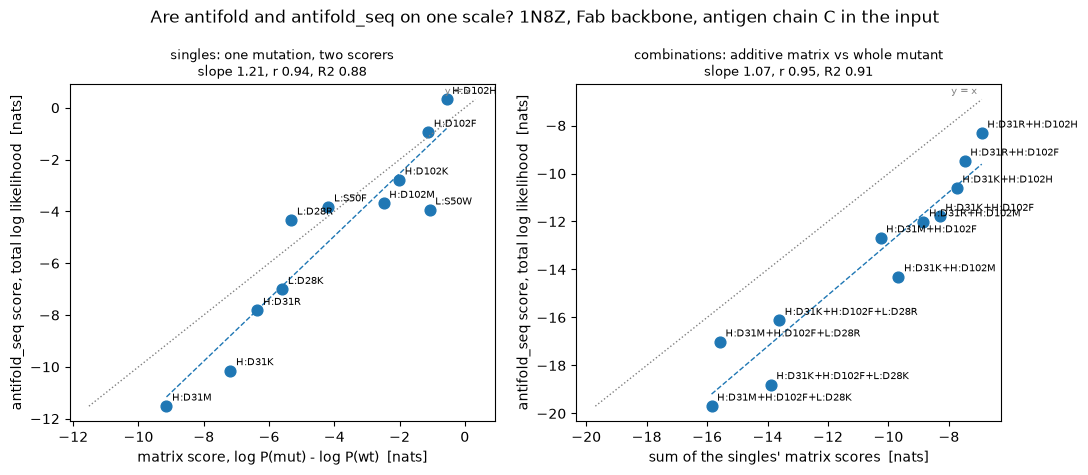

In [19]:
try:
    import matplotlib.pyplot as plt
except ModuleNotFoundError:
    plt = None
    print("matplotlib is not installed, so the two plots are skipped.")
    print("The fits above are the result; the plots only show their shape.")

if plt is not None:
    figure, axes = plt.subplots(1, 2, figsize=(11, 4.8))
    series = [
        (both["score_matrix"], both["score_antifold_seq"], both["label"],
         "matrix score, log P(mut) - log P(wt)  [nats]",
         "singles: one mutation, two scorers"),
        (usable["additive_matrix"], usable["score_antifold_seq"], usable["label"],
         "sum of the singles' matrix scores  [nats]",
         "combinations: additive matrix vs whole mutant"),
    ]
    for axis, (x, y, labels, xlabel, title), stats in zip(axes, series, panels.values()):
        x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
        axis.scatter(x, y, s=60)
        for xi, yi, label in zip(x, y, labels):
            axis.annotate(label, (xi, yi), fontsize=7, xytext=(4, 4), textcoords="offset points")
        span = np.linspace(min(x.min(), y.min()), max(x.max(), y.max()), 2)
        axis.plot(span, span, linestyle=":", linewidth=1, color="grey")
        axis.annotate("y = x", (span[-1], span[-1]), fontsize=7, color="grey",
                      xytext=(-22, 4), textcoords="offset points")
        line = np.linspace(x.min(), x.max(), 2)
        axis.plot(line, stats["slope"] * line + stats["intercept"], linestyle="--", linewidth=1)
        axis.set_xlabel(xlabel)
        axis.set_ylabel("antifold_seq score, total log likelihood  [nats]")
        axis.set_title(f"{title}\nslope {stats['slope']:.2f}, r {stats['pearson']:.2f}, "
                       f"R2 {stats['r2']:.2f}", fontsize=9)
    figure.suptitle("Are antifold and antifold_seq on one scale? 1N8Z, Fab backbone, antigen chain C in the input")
    figure.tight_layout()
    plt.show()

In [20]:
# The verdict, read off the two fits against the criterion in the parameters.
low, high = SLOPE_NEAR_ONE
verdicts = {}
for name, stats in panels.items():
    slope_ok = stats["slope"] == stats["slope"] and low <= stats["slope"] <= high
    gain = stats["quadratic_gain"]
    linear_ok = gain != gain or gain < LINEARITY_GAIN
    verdicts[name] = bool(slope_ok and linear_ok)
    print(name)
    print(f"  slope {stats['slope']:.3f} in [{low}, {high}]: {'yes' if slope_ok else 'NO'}")
    print(f"  linear (a quadratic term buys < {LINEARITY_GAIN} R^2): "
          f"{'yes' if linear_ok else 'NO'} (gain {gain:+.4f})")
    print(f"  strength: r {stats['pearson']:+.3f}, R^2 {stats['r2']:.3f}")
    print()

print("=" * 78)
if all(verdicts.values()):
    print("ONE SCALE. Both fits are linear with slope near 1, so the matrix lookup and")
    print("antifold_seq differ by a known constant and a single ranking column over")
    print("singles and combinations together would not reorder anything. Note this is the")
    print("weaker of the two claims Part 5 tests: a slope near 1 on the combinations also")
    print("means antifold_seq is reproducing the additive sum, i.e. the second and")
    print("expensive call bought no non-additivity at all.")
else:
    print("NOT ONE SCALE. The two columns cannot share a ranking column: a cut on a mixed")
    print("column would be a cut on mutation count and chain length as much as on either")
    print("model's opinion. The pipeline has to keep them apart, which is what it already")
    print("does - `matrices.score_candidates` gives a multi-mutation candidate an empty")
    print("cell and a note rather than a sum, and `score_variants` writes `score_antifold`")
    print("and `score_antifold_seq` as separate columns and never averages them. Rank")
    print("singles and combinations within their own column, or recalibrate both onto")
    print("kcal/mol against a measured panel before mixing them.")
print("=" * 78)

singles: matrix vs antifold_seq (n=11)
  slope 1.207 in [0.8, 1.25]: yes
  linear (a quadratic term buys < 0.02 R^2): yes (gain +0.0106)
  strength: r +0.935, R^2 0.875

combinations: additive matrix vs antifold_seq (n=11)
  slope 1.072 in [0.8, 1.25]: yes
  linear (a quadratic term buys < 0.02 R^2): NO (gain +0.0215)
  strength: r +0.953, R^2 0.908

NOT ONE SCALE. The two columns cannot share a ranking column: a cut on a mixed
column would be a cut on mutation count and chain length as much as on either
model's opinion. The pipeline has to keep them apart, which is what it already
does - `matrices.score_candidates` gives a multi-mutation candidate an empty
cell and a note rather than a sum, and `score_variants` writes `score_antifold`
and `score_antifold_seq` as separate columns and never averages them. Rank
singles and combinations within their own column, or recalibrate both onto
kcal/mol against a measured panel before mixing them.


## Part 5 - the measured epistasis, as the yardstick

Part 4 measures how far `antifold_seq` departs from the additive matrix sum.
That number means nothing on its own: a scorer *should* depart from additivity
if the real molecule does. So the question is how big the real departure is in
this panel, and whether it is even resolvable above the measurement.

This panel is unusually good for that. The singles and the combinations were
measured on the same instrument against the same batch-matched parent, so

    epistasis = ddG(combination) - sum of its singles' ddG

is a difference of numbers on one scale. Across the 7 doubles and 4 triples it
comes to **mean +0.057, sd 0.186 kcal/mol, max +0.37**, against a **median
measurement SD of 0.165 kcal/mol** - recomputed below from the file rather than
quoted, with the propagated uncertainty of each sum carried through so that
"resolvable" is a number and not an impression.

> The brief for this part arrived truncated mid-sentence ("...against a median
> measurement SD"). The reading taken here is the one the numbers support: the
> measured non-additivity in this panel is the yardstick that Part 4's
> model-side non-additivity is held against, and the median measurement SD is
> what says whether the yardstick itself is resolved. Both the panel figures and
> the median SD are recomputed from the file and checked against the quoted
> values, so a different intended reading can be re-run off the same table.

In [21]:
# Measured epistasis, with the uncertainty of the additive sum propagated.
measured_single = {row.mutations[0]: (row.ddg, row.ddg_sd) for row in singles.itertuples()}

rows = []
for row in panel[panel["n_mut"] > 1].itertuples():
    parts = [measured_single.get(m) for m in row.mutations]
    if any(p is None for p in parts):
        continue
    additive = sum(ddg for ddg, _ in parts)
    additive_sd = float(np.sqrt(sum(sd ** 2 for _, sd in parts)))
    rows.append({
        "label": row.label, "n_mut": row.n_mut, "ddg": row.ddg, "ddg_sd": row.ddg_sd,
        "additive": additive, "additive_sd": additive_sd,
        "epistasis": row.ddg - additive,
        # the difference's own SD: the sum's, with the combination's joined to it
        "epistasis_sd": float(np.sqrt(additive_sd ** 2 + row.ddg_sd ** 2)),
    })
measured = pd.DataFrame(rows)
measured["z"] = measured["epistasis"] / measured["epistasis_sd"]
measured = measured.sort_values("epistasis")

print(f"{'variant':<30}{'n':>2}{'ddG':>8}{'sum of singles':>16}{'epistasis':>11}{'+-':>7}{'z':>7}")
print("-" * 81)
for row in measured.itertuples():
    print(f"{row.label:<30}{row.n_mut:>2}{row.ddg:>8.2f}{row.additive:>16.2f}"
          f"{row.epistasis:>+11.3f}{row.epistasis_sd:>7.2f}{row.z:>+7.2f}")
print("-" * 81)

observed = {
    "mean": float(measured["epistasis"].mean()),
    "sd": float(measured["epistasis"].std(ddof=1)),
    "max": float(measured["epistasis"].max()),
    "median_measurement_sd": float(panel["ddg_sd"].median()),
}
median_propagated = float(measured["epistasis_sd"].median())
print(f"{len(measured)} combinations: epistasis mean {observed['mean']:+.3f}, "
      f"sd {observed['sd']:.3f}, max {observed['max']:+.3f}, "
      f"min {measured['epistasis'].min():+.3f} kcal/mol")
print(f"median measurement SD across the panel:      {observed['median_measurement_sd']:.3f} kcal/mol")
print(f"median propagated SD of an epistasis value:  {median_propagated:.3f} kcal/mol")

drift = {k: observed[k] - REPORTED_EPISTASIS[k] for k in REPORTED_EPISTASIS}
if any(abs(v) > TOLERANCE for v in drift.values()):
    raise AssertionError(
        f"the panel figures this notebook was handed {REPORTED_EPISTASIS} do not match the "
        f"file: {observed} (differences {drift}). The yardstick and the data have come "
        "apart; do not read the comparison below until that is resolved."
    )
print(f"\nmatches the quoted figures {REPORTED_EPISTASIS} to within {TOLERANCE}.")

resolved = measured[measured["z"].abs() >= 2]
print(f"\ncombinations whose epistasis is 2 sd or more from zero: {len(resolved)} of "
      f"{len(measured)}" + (f" ({', '.join(resolved['label'])})" if len(resolved) else ""))
print(f"sd of the epistasis ({observed['sd']:.3f}) over the median propagated SD "
      f"({median_propagated:.3f}): ratio {observed['sd'] / median_propagated:.2f}")

variant                        n     ddG  sum of singles  epistasis     +-      z
---------------------------------------------------------------------------------
H:D31M+H:D102F+L:D28R          3   -1.67           -1.42     -0.250   0.37  -0.67
H:D31M+H:D102F+L:D28K          3   -1.78           -1.63     -0.150   0.32  -0.47
H:D31M+H:D102F                 2   -1.25           -1.11     -0.140   0.32  -0.43
H:D31R+H:D102M                 2   -1.06           -1.06     +0.000   0.23  +0.00
H:D31K+H:D102F+L:D28R          3   -1.85           -1.88     +0.030   0.41  +0.07
H:D31K+H:D102F+L:D28K          3   -2.04           -2.09     +0.050   0.33  +0.15
H:D31K+H:D102M                 2   -1.04           -1.17     +0.130   0.29  +0.45
H:D31R+H:D102F                 2   -1.31           -1.46     +0.150   0.28  +0.54
H:D31R+H:D102H                 2   -1.09           -1.28     +0.190   0.25  +0.75
H:D31K+H:D102H                 2   -1.14           -1.39     +0.250   0.32  +0.78
H:D31K+H:D102F  

In [22]:
# The model side, in the same units. Two conversions, both stated: kcal/mol per
# nat from the fit of ddG on each scorer over the candidates it can score, and
# then each scorer's own non-additivity expressed in kcal/mol.
seq_fit = metrics.magnitude_agreement(panel_scored["score_antifold_seq"].to_numpy(),
                                      panel_scored["ddg"].to_numpy())
matrix_fit = metrics.magnitude_agreement(scored["score_matrix"].to_numpy(),
                                         scored["ddg"].to_numpy())
kcal_per_nat_seq = abs(seq_fit["slope"])

print(f"calibration, ddG on antifold_seq over {int(seq_fit['n'])} variants: "
      f"{seq_fit['slope']:+.4f} kcal/mol per nat, R^2 {seq_fit['r2']:.3f}")
print(f"calibration, ddG on the matrix score over {int(matrix_fit['n'])} singles: "
      f"{matrix_fit['slope']:+.4f} kcal/mol per nat, R^2 {matrix_fit['r2']:.3f}")
print()

# antifold_seq's own non-additivity: score(combination) minus the sum of its
# singles' antifold_seq scores. The repo's own helper, which splits a variant_id
# on '+' and drops anything whose parts are not all present.
frame_all = seq_scores.frame
seq_epistasis = _diagnostics.epistasis(
    frame_all[frame_all["variant_id"].isin(comparison["variant_id"])],
    frame_all[frame_all["variant_id"].isin(singles["variant_id"])],
    "score_antifold_seq",
)
seq_epistasis["kcal"] = seq_epistasis["epistasis"] * kcal_per_nat_seq

# And the cross-scorer residual Part 4 plotted, in the same converted units.
cross = usable.assign(residual=usable["score_antifold_seq"] - usable["additive_matrix"])
cross["kcal"] = cross["residual"] * kcal_per_nat_seq

print(f"{'source of non-additivity':<44}{'n':>4}{'mean':>12}{'sd':>12}{'max |.|':>12}")
print("-" * 84)
for name, column in [
    ("measured, kcal/mol", measured["epistasis"]),
    ("antifold_seq vs its own singles, nats", seq_epistasis["epistasis"]),
    ("antifold_seq vs its own singles, kcal/mol", seq_epistasis["kcal"]),
    ("antifold_seq vs additive matrix, nats", cross["residual"]),
    ("antifold_seq vs additive matrix, kcal/mol", cross["kcal"]),
]:
    v = np.asarray(column, dtype=float)
    v = v[np.isfinite(v)]
    if not len(v):
        print(f"{name:<44}{0:>4}{'-':>12}{'-':>12}{'-':>12}")
        continue
    sd = v.std(ddof=1) if len(v) > 1 else float("nan")
    print(f"{name:<44}{len(v):>4}{v.mean():>+12.3f}{sd:>12.3f}{np.abs(v).max():>12.3f}")
print("-" * 84)
print(f"the yardstick: measured epistasis sd {observed['sd']:.3f} kcal/mol, "
      f"max |.| {np.abs(measured['epistasis']).max():.3f}")

calibration, ddG on antifold_seq over 22 variants: +0.0911 kcal/mol per nat, R^2 0.559
calibration, ddG on the matrix score over 11 singles: +0.0084 kcal/mol per nat, R^2 0.002

source of non-additivity                       n        mean          sd     max |.|
------------------------------------------------------------------------------------
measured, kcal/mol                            11      +0.057       0.186       0.370
antifold_seq vs its own singles, nats         11      -0.548       0.233       0.817
antifold_seq vs its own singles, kcal/mol     11      -0.050       0.021       0.074
antifold_seq vs additive matrix, nats         11      -2.974       1.176       4.907
antifold_seq vs additive matrix, kcal/mol     11      -0.271       0.107       0.447
------------------------------------------------------------------------------------
the yardstick: measured epistasis sd 0.186 kcal/mol, max |.| 0.370


In [23]:
# Three statements, each read off the numbers above and each with the number in it.
def sd_of(column):
    v = np.asarray(column, dtype=float)
    v = v[np.isfinite(v)]
    return float(v.std(ddof=1)) if len(v) > 1 else float("nan")


seq_sd_nats = sd_of(seq_epistasis["epistasis"])
seq_sd_kcal = sd_of(seq_epistasis["kcal"])
cross_sd_kcal = sd_of(cross["kcal"])

print("1. Is the measured epistasis resolved?")
print(f"   sd {observed['sd']:.3f} kcal/mol against a median propagated SD of "
      f"{median_propagated:.3f}; {len(resolved)} of {len(measured)} combinations are 2 sd")
print("   from zero.")
if observed["sd"] <= median_propagated:
    print("   The spread of the epistasis does not exceed its own uncertainty. This panel is")
    print("   consistent with additivity, and it cannot validate a scorer's epistasis - only")
    print("   its additivity. A scorer that reproduced the additive sum exactly would be")
    print("   indistinguishable here from one that got the real coupling right.")
else:
    print("   The spread exceeds its uncertainty, so there is real non-additivity to predict.")
print()

print("2. How does antifold_seq's own non-additivity compare?")
print(f"   sd {seq_sd_kcal:.3f} kcal/mol-equivalent (from {seq_sd_nats:.2f} nats at "
      f"{kcal_per_nat_seq:.4f} kcal/mol per nat), against the measured {observed['sd']:.3f}.")
ratio = seq_sd_kcal / observed["sd"] if observed["sd"] else float("nan")
print(f"   ratio {ratio:.1f}x.")
if ratio == ratio and ratio > 3:
    print("   Far larger than anything measured here. Whatever antifold_seq's departure from")
    print("   its own singles tracks, it is not this panel's epistasis: at this size it is")
    print("   dominated by the scorer's construction - a per-residue average times a chain")
    print("   length, so one substitution moves the whole chain's likelihood - rather than by")
    print("   a coupling between two CDR positions.")
elif ratio == ratio and ratio < 0.33:
    print("   Far smaller than the measured spread: the scorer is close to additive by")
    print("   construction, so re-scoring a combination buys little over summing its singles.")
else:
    print("   The same order as the measured spread, the one case where the per-variant call")
    print("   could be carrying real information. n is 11; treat it as a hint, not a result.")
print()

print("3. What does that make of Part 4?")
print(f"   The cross-scorer residual - antifold_seq minus the additive matrix sum - has sd")
print(f"   {cross_sd_kcal:.3f} kcal/mol-equivalent against a measured yardstick of "
      f"{observed['sd']:.3f}.")
if cross_sd_kcal == cross_sd_kcal and cross_sd_kcal > 3 * observed["sd"]:
    print("   The gap between the two columns is an order above the largest real effect in the")
    print("   panel, so it is a difference of scales and not a difference of physics. That is")
    print("   the decisive argument for keeping the two columns apart: a shortlist cut on a")
    print("   mixed column would be cut mostly on units.")
else:
    print("   The gap is within the range of real effects, so it cannot be dismissed as a")
    print("   scale artifact on these numbers alone; a larger panel would be needed.")

1. Is the measured epistasis resolved?
   sd 0.186 kcal/mol against a median propagated SD of 0.322; 0 of 11 combinations are 2 sd
   from zero.
   The spread of the epistasis does not exceed its own uncertainty. This panel is
   consistent with additivity, and it cannot validate a scorer's epistasis - only
   its additivity. A scorer that reproduced the additive sum exactly would be
   indistinguishable here from one that got the real coupling right.

2. How does antifold_seq's own non-additivity compare?
   sd 0.021 kcal/mol-equivalent (from 0.23 nats at 0.0911 kcal/mol per nat), against the measured 0.186.
   ratio 0.1x.
   Far smaller than the measured spread: the scorer is close to additive by
   construction, so re-scoring a combination buys little over summing its singles.

3. What does that make of Part 4?
   The cross-scorer residual - antifold_seq minus the additive matrix sum - has sd
   0.107 kcal/mol-equivalent against a measured yardstick of 0.186.
   The gap is within th

## Part 6 - antigen against no antigen

The same 22 variants, the same weights, the same code, with and without chain C in the input. Two things are
being checked. First that the antigen moved the scores at all, which the control cells in Parts 2 and 3 test
directly. Then whether it moved them towards the measurements: Spearman against -ddG, sign-corrected, as in 03.

The saved numbers are 03's own, read off its outputs. The live control re-runs 03's configuration here, so
a disagreement between the two is a difference in environment or weights, not an effect of the antigen.


In [24]:
def rho_of(frame, subset):
    part = frame[subset].dropna(subset=["score_antifold_seq"])
    return metrics.spearman(part["score_antifold_seq"].to_numpy(), -part["ddg"].to_numpy())


live = {
    "combos": (rho_of(panel_control, panel_control["n_mut"] > 1), rho_combos),
    "all22": (rho_of(panel_control, panel_control["n_mut"] > 0), rho_of(panel_scored, panel_scored["n_mut"] > 0)),
}
ref = NO_ANTIGEN_REFERENCE
rows6 = [
    ("matrix lookup, 11 singles", ref["singles_rho"], None, rho),
    ("antifold_seq, 11 combinations", ref["combos_rho"], live["combos"][0], live["combos"][1]),
    ("antifold_seq, all 22 in one ranking", ref["all22_rho"], live["all22"][0], live["all22"][1]),
]
print(f"{'Spearman, sign-corrected':<40}{'03 saved':>10}{'no antigen, live':>18}{'antigen C':>12}{'change':>9}")
print("-" * 89)
for name, saved, control, with_ag in rows6:
    base = saved if control is None else control
    control_text = "-" if control is None else f"{control:+.3f}"
    print(f"{name:<40}{saved:>+10.3f}{control_text:>18}{with_ag:>+12.3f}{with_ag - base:>+9.3f}")
print("-" * 89)

for name, saved, control, _ in rows6:
    if control is not None and abs(control - saved) > REFERENCE_TOLERANCE:
        print(f"NOTE: the live no-antigen control gives {control:+.3f} for '{name}', 03 saved {saved:+.3f}. "
              "The control does not reproduce 03, so compare the antigen run with the live control only.")

both_scored = panel_scored.merge(panel_control[["variant_id", "score_antifold_seq"]], on="variant_id",
                                 suffixes=("", "_noantigen")).dropna(subset=["score_antifold_seq", "score_antifold_seq_noantigen"])
shift = (both_scored["score_antifold_seq"] - both_scored["score_antifold_seq_noantigen"]).to_numpy()
print()
print(f"antifold_seq, antigen minus no antigen, over {len(both_scored)} variants, nats: "
      f"mean {shift.mean():+.3f}, sd {shift.std(ddof=1):.3f}, largest |.| {np.abs(shift).max():.3f}")
print(f"rank agreement of the two antifold_seq columns, Spearman: "
      f"{metrics.spearman(both_scored['score_antifold_seq'].to_numpy(), both_scored['score_antifold_seq_noantigen'].to_numpy()):+.3f}")
print()
print(f"the two measured losses {EXPECTED_WORST} at the bottom of the matrix ranking: "
      f"{'HELD' if set(EXPECTED_WORST) == bottom_two else 'DID NOT HOLD'} with the antigen "
      f"(03 without it: {'HELD' if ref['worst_two_at_bottom'] else 'DID NOT HOLD'})")
print(f"one scale (Part 4's verdict): {'yes' if all(verdicts.values()) else 'NO'} with the antigen "
      f"(03 without it: {'yes' if ref['one_scale'] else 'NO'})")


Spearman, sign-corrected                  03 saved  no antigen, live   antigen C   change
-----------------------------------------------------------------------------------------
matrix lookup, 11 singles                   +0.291                 -      +0.045   -0.246
antifold_seq, 11 combinations               -0.655            -0.655      -0.609   +0.045
antifold_seq, all 22 in one ranking         -0.667            -0.667      -0.748   -0.081
-----------------------------------------------------------------------------------------

antifold_seq, antigen minus no antigen, over 22 variants, nats: mean -0.921, sd 1.150, largest |.| 3.023
rank agreement of the two antifold_seq columns, Spearman: +0.972

the two measured losses ('L:S50F', 'L:S50W') at the bottom of the matrix ranking: DID NOT HOLD with the antigen (03 without it: DID NOT HOLD)
one scale (Part 4's verdict): NO with the antigen (03 without it: NO)


## What this notebook establishes

Fill in from the run above - the numbers, not the expectation. Three of them
change what the pipeline does:

1. **The numbering.** `CHAIN_MAP = {"H": "B", "L": "A"}`, positions straight
   across, checked at every site the panel touches and re-checked by
   `enumerate_variants`. That is the fact to reuse: further work on this panel
   can take the mapping as established, and the check as the thing to re-run if
   either file changes.
2. **The ranking.** Spearman for the matrix lookup on 11 singles, for
   `antifold_seq` on 11 combinations, and whether `L:S50F` and `L:S50W` - the
   panel's only two losses - come out at the bottom. All of it measured with
   chain C in the input; Part 6 sets it against the same run without. A Fab
   structure in a complex is still one conformation of a few variants, which is
   the limit on how far any of it carries to a binding campaign.
3. **The two columns.** Whether `score_antifold` and `score_antifold_seq` can
   share a ranking, and, if they cannot, that the pipeline's existing refusal to
   sum singles is load-bearing rather than fastidious.

What this panel cannot do, whatever the numbers come out as: validate a scorer's
epistasis. The measured non-additivity here sits at the scale of the measurement
itself, so agreeing with it is not evidence of having modelled a coupling, and
disagreeing with it is not evidence of having failed to. The next experiment that
moves either question is a panel whose epistasis is larger than its error bars.
The antigen-aware re-run is this notebook; what Part 6 shows is whether it was worth the change.